# Actividad — Valores atípicos y EDA con California Housing
**Aprendizaje Supervisado · Unidad 1 · Preparación de datos y análisis exploratorio (EDA)**

**Qué haremos.** En la presentación vimos las herramientas del EDA. Hoy las usarás sobre un conjunto real y, sobre todo,
**tomarás decisiones**: ¿qué hago con cada valor raro? ¿en qué variables puedo confiar para una correlación?

| Parte | Pregunta que responde | Tema de la presentación |
|---|---|---|
| 1 | ¿Qué hay en el conjunto de datos? | Tipos de variable, el dataset |
| 2 | ¿Qué dicen $\bar x$, mediana, $s$, asimetría y curtosis? | Estadística descriptiva |
| 3 | ¿Qué forma tiene cada variable? | Histogramas |
| 4 | ¿Cuántos atípicos marcan los boxplots y la regla del IQR? | Boxplot y $1.5\cdot\mathrm{IQR}$ |
| 5 | ¿Qué son esas filas extremas? ¿error, dato raro o tope? | Un atípico, ¿qué hago con él? |
| 6 | ¿Qué efecto tienen los topes (5.0 y 52)? | Censura |
| 7 | ¿Qué cambia si recorto o aplico logaritmo? | Transformaciones |
| 8 | ¿Cómo se relacionan las variables con el precio? | Análisis bivariado |
| 9 | ¿Qué dice la matriz de correlación? ¿hay multicolinealidad? | Matriz y heatmap |
| 10 | Resumen y entregable | Receta de EDA |

**Tiempo estimado:** 40–50 minutos de trabajo individual.

**Entregable:** este notebook ejecutado, con sus respuestas en las celdas ✏️, y la **tabla de decisiones**
de la Parte 10: *variable · % de atípicos · decisión · justificación*.

**Cómo trabajar.** Ejecuta las celdas en orden. Donde dice ✏️ hay una pregunta o un parámetro que debes cambiar tú
(escribe tus respuestas en la celda de texto que sigue a la pregunta, bajo «**Respuesta:**»).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
})
AZUL, NARANJA, VERDE, ROJO = "#065A82", "#E07A1F", "#02C39A", "#C0392B"
pd.set_option("display.precision", 3)
warnings.filterwarnings("ignore", message=".*vert.*")   # aviso de versiones nuevas de matplotlib sobre boxplot(vert=...)

---
## Parte 1 — Cargar y conocer los datos

El conjunto **California Housing** (Pace y Barry, 1997) viene del censo de 1990. **Cada fila es un distrito censal**
(no una vivienda): sus valores son medianas o promedios de muchos hogares.

| Variable | Qué describe |
|---|---|
| `MedInc` | ingreso mediano del distrito (en decenas de miles de USD) |
| `HouseAge` | edad mediana de las viviendas (años) |
| `AveRooms` | habitaciones promedio por hogar |
| `AveBedrms` | dormitorios promedio por hogar |
| `Population` | número de habitantes del distrito |
| `AveOccup` | ocupantes promedio por hogar |
| `Latitude`, `Longitude` | ubicación del distrito |
| `MedHouseVal` | **objetivo**: valor mediano de la vivienda (en cientos de miles de USD) |

> La primera vez, `fetch_california_housing` descarga el archivo (≈1 MB) y lo guarda en `~/scikit_learn_data`; se necesita conexión a internet.

In [2]:
data = fetch_california_housing(as_frame=True)
df = data.frame.copy()          # trabajamos sobre una copia: el original queda intacto
print("Forma (filas, columnas):", df.shape)
df.head()

Forma (filas, columnas): (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.325,41.0,6.984,1.024,322.0,2.556,37.88,-122.23,4.526
1,8.301,21.0,6.238,0.972,2401.0,2.110,37.86,-122.22,3.585
2,7.257,52.0,8.288,1.073,496.0,2.802,37.85,-122.24,3.521
3,5.643,52.0,5.817,1.073,558.0,2.548,37.85,-122.25,3.413
4,3.846,52.0,6.282,1.081,565.0,2.181,37.85,-122.25,3.422


In [3]:
df.info()
print("\nFaltantes por columna:")
print(df.isna().sum().to_string())
print("\nFilas duplicadas:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Faltantes por columna:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0

Filas duplicadas: 0


✏️ **Pregunta 1.1.** ¿Cuántas filas y columnas hay? ¿Hay faltantes o duplicados? ¿Qué tipo de variable es cada columna (continua, discreta…)?

✏️ **Pregunta 1.2.** Cada fila es un *distrito*, no una casa. ¿Qué consecuencia tiene esto cuando una variable dice «promedio» o «mediana»?
(Pista: ¿cómo podría ser un promedio de 140 habitaciones por hogar?)

**Respuesta:**

Hay **20 640 filas y 9 columnas**, sin valores faltantes ni filas duplicadas. `Population` y
`HouseAge` son variables numéricas discretas aunque pandas las almacene como `float`; `Latitude`
y `Longitude` son coordenadas continuas; `MedInc`, `AveRooms`, `AveBedrms`, `AveOccup` y
`MedHouseVal` se tratan como continuas. `MedHouseVal` es la variable objetivo.

Cada registro resume un distrito. Por eso, un promedio extremo no describe una casa individual:
puede aparecer cuando el denominador (número de hogares) es muy pequeño o cuando el distrito
representa una residencia colectiva. Antes de marcarlo como error hay que revisar la fila completa.


---
## Parte 2 — Estadística descriptiva: media, varianza, asimetría y curtosis

Recordatorio (con $z_i = (x_i-\bar x)/s$):

$$\gamma_1=\frac1n\sum_{i=1}^n z_i^3 \quad(\text{asimetría}),\qquad \kappa-3=\frac1n\sum_{i=1}^n z_i^4-3 \quad(\text{curtosis en exceso}).$$

`pandas` calcula ambas con una pequeña corrección para muestras finitas; con $n=20\,640$ la diferencia es mínima.

In [4]:
def resumen(d):
    t = d.agg(["mean", "median", "std", "min", "max"]).T
    t["asimetria"] = d.skew()
    t["curtosis_exc"] = d.kurt()
    t["media - mediana"] = t["mean"] - t["median"]
    return t

resumen(df).round(2)

,mean,median,std,min,max,asimetria,curtosis_exc,media - mediana
MedInc,3.87,3.53,1.90,0.50,15.00,1.65,4.95,0.34
HouseAge,28.64,29.00,12.59,1.00,52.00,0.06,-0.80,-0.36
AveRooms,5.43,5.23,2.47,0.85,141.91,20.70,879.35,0.20
AveBedrms,1.10,1.05,0.47,0.33,34.07,31.32,1636.71,0.05
Population,1425.48,1166.00,1132.46,3.00,35682.00,4.94,73.55,259.48
AveOccup,3.07,2.82,10.39,0.69,1243.33,97.64,10651.01,0.25
Latitude,35.63,34.26,2.14,32.54,41.95,0.47,-1.12,1.37
Longitude,-119.57,-118.49,2.00,-124.35,-114.31,-0.30,-1.33,-1.08
MedHouseVal,2.07,1.80,1.15,0.15,5.00,0.98,0.33,0.27


In [5]:
# Comprobación «a mano» con MedInc: lo que hace pandas, paso por paso
x = df["MedInc"]
z = (x - x.mean()) / x.std(ddof=0)          # puntaje z
g1 = (z ** 3).mean()                         # asimetría
exceso = (z ** 4).mean() - 3                 # curtosis en exceso
print(f"a mano : asimetría = {g1:.4f}   curtosis en exceso = {exceso:.4f}")
print(f"pandas : asimetría = {x.skew():.4f}   curtosis en exceso = {x.kurt():.4f}")

a mano : asimetría = 1.6465   curtosis en exceso = 4.9510
pandas : asimetría = 1.6467   curtosis en exceso = 4.9525


In [6]:
# ¿Qué variables tienen la forma «más rara»? ordenamos por |asimetría|
resumen(df)[["asimetria", "curtosis_exc"]].abs().sort_values("asimetria", ascending=False).round(1)

,asimetria,curtosis_exc
AveOccup,97.6,10651.0
AveBedrms,31.3,1636.7
AveRooms,20.7,879.4
Population,4.9,73.6
MedInc,1.6,5.0
MedHouseVal,1.0,0.3
Latitude,0.5,1.1
Longitude,0.3,1.3
HouseAge,0.1,0.8


✏️ **Pregunta 2.1.** En `MedInc`, ¿qué signo tiene `media - mediana`? ¿Concuerda con el signo de la asimetría? Explícalo con una frase.

✏️ **Pregunta 2.2.** Menciona las **tres variables** con mayor asimetría. ¿Qué dice la curtosis de la que tiene el valor más grande?
(Recuerda: la curtosis alta habla de *colas pesadas*, es decir, de valores extremos.)

✏️ **Pregunta 2.3.** `AveOccup` tiene media ≈ 3 pero un máximo de más de 1 000. ¿Cuántas desviaciones estándar por encima de la media está ese máximo? Calcúlalo en la celda de abajo.

**Respuesta:**

En `MedInc`, `media - mediana` es positivo (aprox. 0.34) y la asimetría también es positiva
(1.65). Es coherente: la cola de ingresos altos desplaza la media hacia la derecha.

Las tres variables más asimétricas son `AveOccup` (97.64), `AveBedrms` (31.32) y `AveRooms`
(20.70). `AveOccup` tiene además una curtosis en exceso cercana a 10 651, señal de una cola
dominada por muy pocos valores extremos. Su máximo está a unas **119 desviaciones estándar** de
la media; este resultado también muestra que media y desviación estándar dejan de ser resúmenes
robustos en esta variable.


In [7]:
# ✏️ Pregunta 2.3: puntaje z del valor máximo de AveOccup
v = df["AveOccup"]
z_max = (v.max() - v.mean()) / v.std()
print(f"El máximo de AveOccup está a {z_max:.0f} desviaciones estándar de la media")

El máximo de AveOccup está a 119 desviaciones estándar de la media


---
## Parte 3 — Forma de cada variable: histogramas

Dibujamos la media (naranja, discontinua) y la mediana (verde). Para poder **ver** la forma, recortamos el 0.5 % superior
*solo en el dibujo* (los datos no se modifican).

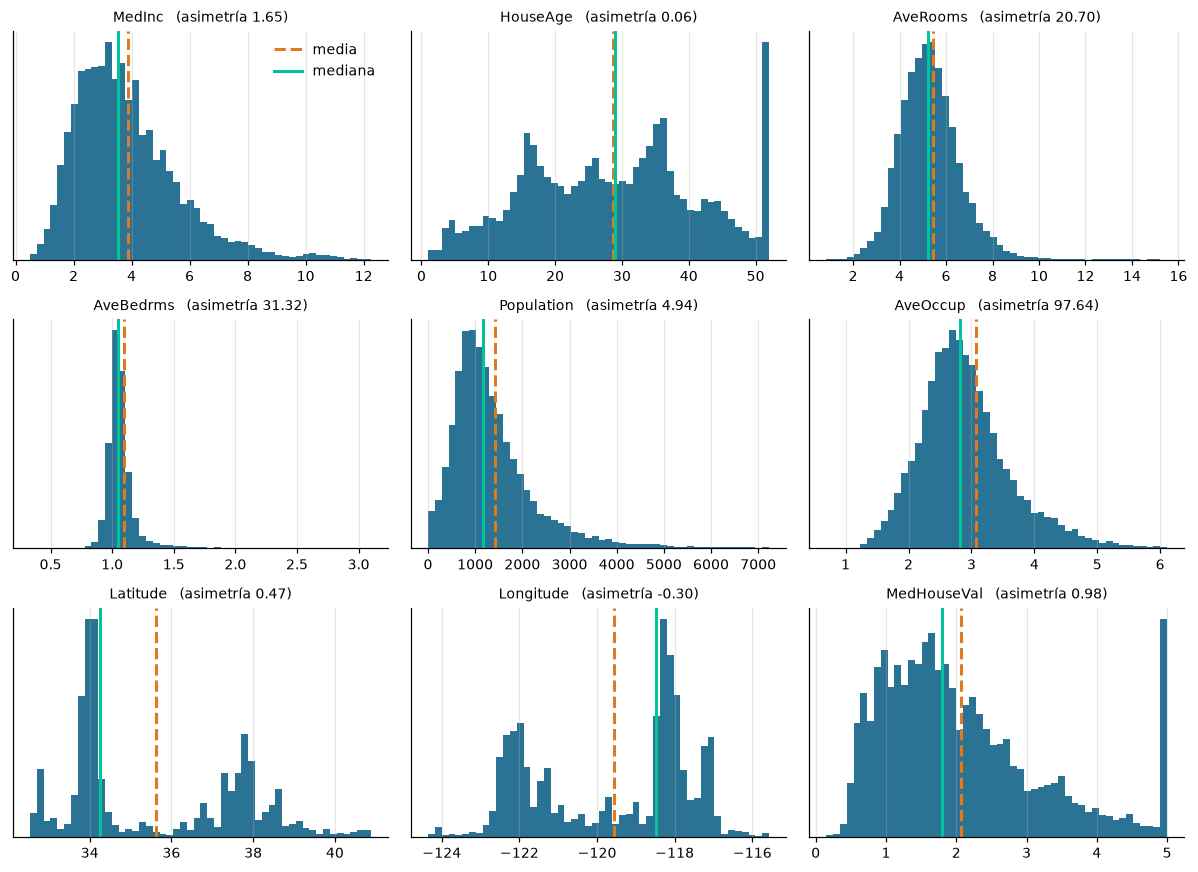

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(11, 8))
for ax, c in zip(axes.ravel(), df.columns):
    x = df[c]
    tope = x.quantile(0.995)                       # ✏️ prueba con 1.0 para AveOccup y compara
    ax.hist(x[x <= tope], bins=50, color=AZUL, alpha=0.85)
    ax.axvline(x.mean(), color=NARANJA, lw=2, ls="--", label="media")
    ax.axvline(x.median(), color=VERDE, lw=2, label="mediana")
    ax.set_title(f"{c}   (asimetría {x.skew():.2f})", fontsize=9)
    ax.set_yticks([])
axes[0, 0].legend(frameon=False)
plt.tight_layout()
plt.show()

✏️ **Pregunta 3.1.** Describe con una frase la forma de `MedInc`, `HouseAge`, `Population` y `MedHouseVal`.
¿Cuáles tienen una barra «de más» al extremo derecho? (La estudiaremos en la Parte 6.)

✏️ **Pregunta 3.2.** Cambia `tope = x.quantile(0.995)` por `x.quantile(1.0)` y mira `AveOccup`. ¿Qué pasa con el histograma y por qué?

**Respuesta:**

`MedInc` tiene cola derecha; `HouseAge` es casi uniforme y acumula observaciones en 52;
`Population` presenta una cola derecha larga; `MedHouseVal` es asimétrica a la derecha y tiene un
pico en 5.0. Las barras adicionales del extremo derecho aparecen en `HouseAge` y `MedHouseVal` y
corresponden a topes del conjunto de datos.

Al usar el cuantil 1.0 en `AveOccup`, el eje debe llegar hasta 1 243 y casi todas las observaciones
quedan comprimidas en las primeras barras. El recorte al 99.5 % solo era visual y permitía ver la
forma del grueso de los datos sin modificar la tabla.


---
## Parte 4 — Identificar atípicos con boxplots y la regla del IQR

**Regla de Tukey.** Con $Q_1$, $Q_3$ y $\mathrm{IQR}=Q_3-Q_1$, un dato es atípico si cae fuera de

$$[\,Q_1-k\cdot\mathrm{IQR},\ \ Q_3+k\cdot\mathrm{IQR}\,],\qquad k=1.5\ (\text{atípico})\quad\text{o}\quad k=3\ (\text{atípico extremo}).$$

Primero comprobamos con datos simulados qué fracción marca la regla cuando **sí** conocemos la distribución.

In [9]:
def cercas_iqr(s, k=1.5):
    '''Devuelve (cerca inferior, cerca superior) de la regla de Tukey.'''
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rng = np.random.default_rng(0)
for nombre, x in [("normal", rng.normal(size=100_000)), ("lognormal", rng.lognormal(size=100_000))]:
    lo, hi = cercas_iqr(pd.Series(x))
    print(f"{nombre:10s}: {100 * ((x < lo) | (x > hi)).mean():.2f} % de los datos fuera de las cercas")

normal    : 0.72 % de los datos fuera de las cercas
lognormal : 7.82 % de los datos fuera de las cercas


✏️ **Pregunta 4.1.** En la normal, ¿qué porcentaje marca la regla? ¿Y en la lognormal (muy asimétrica)? ¿Qué te dice esto sobre interpretar
«porcentaje de atípicos» en variables con cola larga?

**Respuesta:**

Con la semilla indicada, la regla marca cerca de **0.72 %** en la normal y **7.82 %** en la
lognormal. En una distribución con cola larga, un porcentaje alto de puntos fuera de las cercas no
implica que todos sean errores: la propia forma de la variable puede producirlos. La regla sirve
para localizar casos que requieren revisión, no para borrarlos automáticamente.


In [10]:
def tabla_atipicos(d, k=1.5):
    filas = []
    for c in d.columns:
        lo, hi = cercas_iqr(d[c], k)
        bajo, alto = int((d[c] < lo).sum()), int((d[c] > hi).sum())
        filas.append(dict(variable=c, cerca_inf=lo, cerca_sup=hi, n_bajo=bajo, n_alto=alto,
                          pct_atipicos=100 * (bajo + alto) / len(d), minimo=d[c].min(), maximo=d[c].max()))
    return pd.DataFrame(filas).set_index("variable")

tabla_k15 = tabla_atipicos(df, 1.5)
tabla_k30 = tabla_atipicos(df, 3.0)
K = 1.5
tabla = tabla_k15
print('Cercas con k = 1.5')
display(tabla_k15.round(2))
print('Cercas con k = 3.0')
display(tabla_k30.round(2))

Cercas con k = 1.5


,cerca_inf,cerca_sup,n_bajo,n_alto,pct_atipicos,minimo,maximo
variable,,,,,,,
MedInc,-0.71,8.01,0,681,3.30,0.50,15.00
HouseAge,-10.50,65.50,0,0,0.00,1.00,52.00
AveRooms,2.02,8.47,45,466,2.48,0.85,141.91
AveBedrms,0.87,1.24,188,1236,6.90,0.33,34.07
Population,-620.00,3132.00,0,1196,5.79,3.00,35682.00
AveOccup,1.15,4.56,7,704,3.44,0.69,1243.33
Latitude,28.26,43.38,0,0,0.00,32.54,41.95
Longitude,-127.48,-112.33,0,0,0.00,-124.35,-114.31
MedHouseVal,-0.98,4.82,0,1071,5.19,0.15,5.00


Cercas con k = 3.0


,cerca_inf,cerca_sup,n_bajo,n_alto,pct_atipicos,minimo,maximo
variable,,,,,,,
MedInc,-3.98,11.28,0,140,0.68,0.50,15.00
HouseAge,-39.00,94.00,0,0,0.00,1.00,52.00
AveRooms,-0.39,10.89,0,180,0.87,0.85,141.91
AveBedrms,0.73,1.38,32,692,3.51,0.33,34.07
Population,-2027.00,4539.00,0,421,2.04,3.00,35682.00
AveOccup,-0.13,5.84,0,132,0.64,0.69,1243.33
Latitude,22.59,49.05,0,0,0.00,32.54,41.95
Longitude,-133.17,-106.64,0,0,0.00,-124.35,-114.31
MedHouseVal,-3.16,7.00,0,0,0.00,0.15,5.00


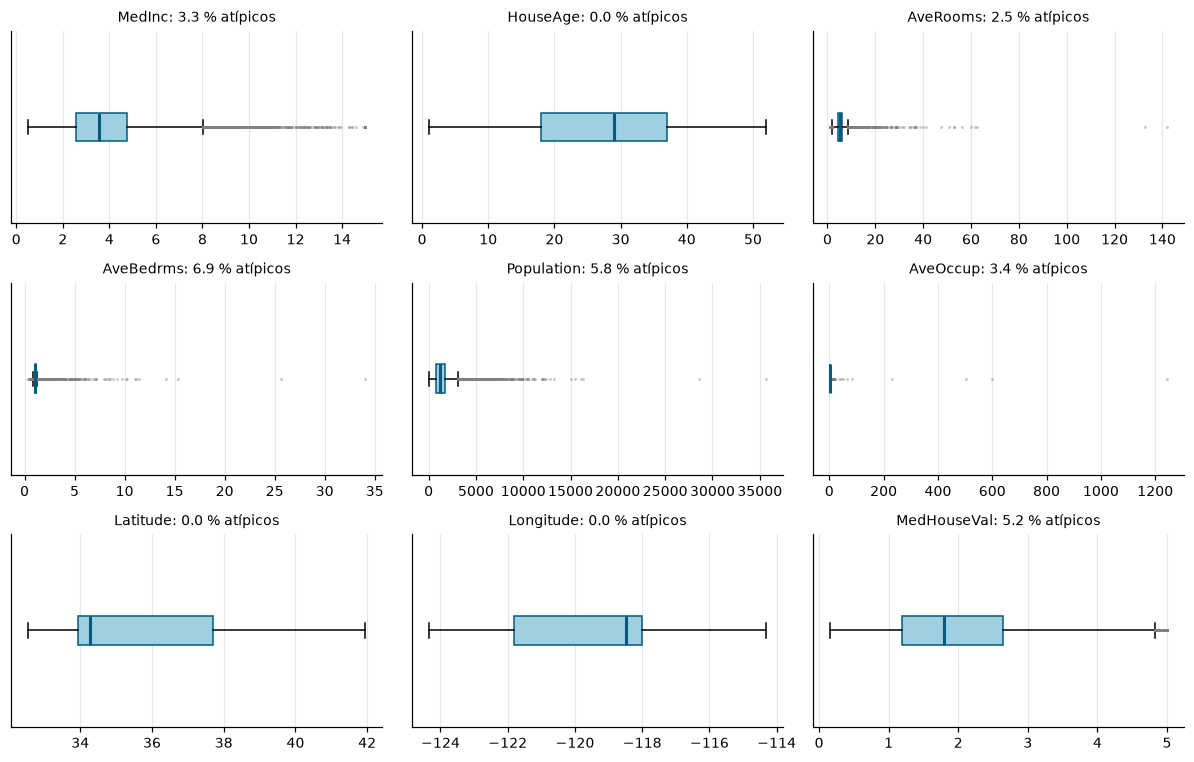

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(11, 7))
for ax, c in zip(axes.ravel(), df.columns):
    ax.boxplot(df[c], vert=False, whis=K, patch_artist=True,
               boxprops=dict(facecolor="#9FD0E0", edgecolor=AZUL), medianprops=dict(color=AZUL, lw=2),
               flierprops=dict(marker="o", markersize=2, markerfacecolor="gray", markeredgecolor="none", alpha=0.4))
    ax.set_yticks([])
    ax.set_title(f"{c}: {tabla.loc[c, 'pct_atipicos']:.1f} % atípicos", fontsize=9)
plt.tight_layout()
plt.show()

✏️ **Pregunta 4.2.** Con $k=1.5$: ¿qué variable tiene el mayor *porcentaje* de atípicos? ¿Cuál tiene el valor más **lejano** (compara `maximo` con `cerca_sup`)?
¿Coinciden? ¿Por qué un porcentaje alto no implica necesariamente valores absurdos?

✏️ **Pregunta 4.3.** Repite con $k=3$. ¿Qué variables casi «se limpian» y cuáles conservan atípicos extremos? ¿Cuáles tienen **0 %** y por qué
(piensa en `Latitude`, `Longitude` y `HouseAge`)?

**Respuesta:**

Con $k=1.5$, `AveBedrms` tiene el porcentaje mayor (6.90 %), seguido de `Population` (5.80 %).
Sin embargo, el valor más alejado de su cerca aparece en `AveOccup`: su máximo es 1 243.33 y la
cerca superior es 4.56. No coinciden porque el porcentaje cuenta cuántos casos quedan fuera,
mientras la distancia mide qué tan extremo es un caso. Una cola moderadamente larga puede aportar
muchos atípicos sin contener un valor tan desproporcionado.

Con $k=3$, `MedInc` baja a 0.68 %, `AveRooms` a 0.87 %, `AveBedrms` a 3.51 %, `Population` a
2.04 % y `AveOccup` a 0.64 %. `HouseAge`, `Latitude`, `Longitude` y `MedHouseVal` quedan en 0 %.
Las coordenadas y la edad ocupan rangos acotados; en `MedHouseVal`, la cerca de 7.00 queda por
encima del tope publicado de 5.0. Aun con $k=3$, los máximos de `AveOccup`, `AveRooms` y
`AveBedrms` siguen siendo extremos claros.


---
## Parte 5 — Inspeccionar las filas extremas: ¿error, dato raro o tope?

La regla del IQR dice **qué es inusual**, no **qué es incorrecto**. Para decidir hay que mirar las filas y razonar con el contexto.
Una pista útil: el número de hogares de un distrito es aproximadamente `Population / AveOccup`.

In [12]:
ext = df.nlargest(5, "AveOccup").copy()
ext["hogares (aprox.)"] = ext["Population"] / ext["AveOccup"]
print("Las 5 filas con más ocupantes por hogar:")
ext[["Population", "AveOccup", "hogares (aprox.)", "AveRooms", "MedHouseVal"]].round(1)

Las 5 filas con más ocupantes por hogar:


,Population,AveOccup,hogares (aprox.),AveRooms,MedHouseVal
19006,7460.0,1243.3,6.0,3.2,1.4
3364,4198.0,599.7,7.0,5.1,0.7
16669,6532.0,502.5,13.0,9.1,3.5
13034,6675.0,230.2,29.0,8.3,2.2
9172,8733.0,83.2,105.0,5.1,1.5


In [13]:
ext2 = df.nlargest(5, "AveRooms").copy()
ext2["hogares (aprox.)"] = ext2["Population"] / ext2["AveOccup"]
print("Las 5 filas con más habitaciones por hogar:")
ext2[["Population", "AveOccup", "hogares (aprox.)", "AveRooms", "AveBedrms", "MedHouseVal"]].round(1)

Las 5 filas con más habitaciones por hogar:


,Population,AveOccup,hogares (aprox.),AveRooms,AveBedrms,MedHouseVal
1914,30.0,2.7,11.0,141.9,25.6,5.0
1979,36.0,2.4,15.0,132.5,34.1,1.6
12447,83.0,1.8,45.0,62.4,14.1,0.9
1913,112.0,2.3,48.0,61.8,11.0,4.4
11862,28.0,1.8,16.0,59.9,15.3,0.7


✏️ **Pregunta 5.1.** Para cada uno de estos casos, clasifícalo y justifica: **(a)** error de captura / imposible, **(b)** dato real pero raro,
**(c)** tope o censura. Fíjate en los hogares aproximados: un distrito con 7 460 personas y ≈6 hogares, ¿qué tipo de lugar podría ser?
(pista: residencias universitarias, cárceles, cuarteles…) ¿Qué distritos con muchas habitaciones por hogar y muy poca población podrían ser?

✏️ **Pregunta 5.2.** ¿Tienen sentido estos distritos para un modelo que predice el **valor de la vivienda** en zonas residenciales normales?
Propón una regla (por ejemplo, un mínimo de hogares) para marcarlos o excluirlos, **y anota cuántas filas afectaría**.

**Respuesta:**

Los máximos de `AveOccup` no parecen simples errores tipográficos: por ejemplo, 7 460 personas y
seis hogares producen 1 243 ocupantes por hogar y son compatibles con una residencia colectiva,
una cárcel o un cuartel. Son datos posibles, pero raros y fuera del significado residencial usual.
Los máximos de `AveRooms` aparecen en distritos de 11 a 48 hogares y muy poca población; pueden
corresponder a hoteles, instituciones o propiedades grandes agregadas. Los valores 5.0 de precio y
52 de edad son otro caso: son topes o censura, no errores ni observaciones libres.

Para un modelo de vivienda residencial, marcaría los distritos con menos de diez hogares y los
separaría del entrenamiento principal, conservándolos para un análisis de sensibilidad. La regla
afecta **51 de 20 640 filas (0.25 %)**. No los eliminaría sin registrar los índices y sin comparar el
desempeño con y sin ellos.


In [14]:
# ✏️ Pregunta 5.2: prueba tu regla aquí (ejemplo: marcar distritos con menos de 10 hogares)
hogares = df["Population"] / df["AveOccup"]
marca = hogares < 10
print(f"Filas marcadas: {marca.sum()} de {len(df)}  ({100 * marca.mean():.2f} %)")
df.loc[marca, ["Population", "AveOccup", "AveRooms", "MedHouseVal"]].describe().round(1)

Filas marcadas: 51 de 20640  (0.25 %)


,Population,AveOccup,AveRooms,MedHouseVal
count,51.0,51.0,51.0,51.0
mean,253.3,40.2,6.4,2.1
std,1183.8,191.0,4.8,1.4
min,3.0,0.8,1.0,0.1
25%,13.0,2.5,3.3,0.8
50%,20.0,3.3,5.1,1.8
75%,32.0,4.9,7.1,3.5
max,7460.0,1243.3,24.5,5.0


---
## Parte 6 — Topes (censura): los picos en 5.0 y 52

En los histogramas había una barra extra al final de `MedHouseVal` y de `HouseAge`: valores **truncados** por la forma en que se publicó
el censo (valores mayores se registran como el tope). No son «atípicos»: son datos **censurados**.

MedHouseVal :   992 filas ≥ 5.0  (4.81 %)
HouseAge    :  1273 filas ≥ 52  (6.17 %)
MedInc      :    51 filas ≥ 15.0  (0.25 %)


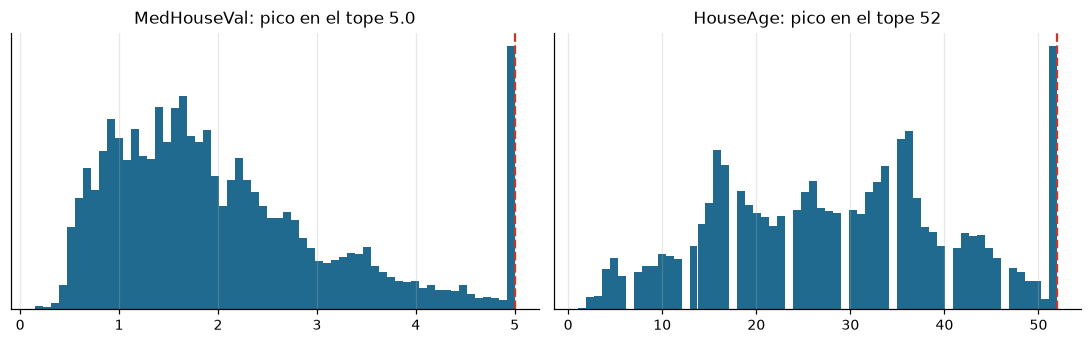

In [15]:
topes = {"MedHouseVal": 5.0, "HouseAge": 52, "MedInc": 15.0}
for c, tope in topes.items():
    n = int((df[c] >= tope).sum())
    print(f"{c:12s}: {n:5d} filas ≥ {tope}  ({100 * n / len(df):.2f} %)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, c in zip(axes, ["MedHouseVal", "HouseAge"]):
    ax.hist(df[c], bins=60, color=AZUL, alpha=0.9)
    ax.axvline(topes[c], color=ROJO, ls="--", lw=1.5)
    ax.set_title(f"{c}: pico en el tope {topes[c]}")
    ax.set_yticks([])
plt.tight_layout()
plt.show()

In [16]:
# ¿Cómo cambia una correlación si «quitamos» las filas con tope?
sin_tope = df[df["MedHouseVal"] < 5.0]
print("r(MedInc, MedHouseVal) con topes :", round(df["MedInc"].corr(df["MedHouseVal"]), 3))
print("r(MedInc, MedHouseVal) sin topes :", round(sin_tope["MedInc"].corr(sin_tope["MedHouseVal"]), 3))
print("Filas que se perderían:", len(df) - len(sin_tope))

r(MedInc, MedHouseVal) con topes : 0.688
r(MedInc, MedHouseVal) sin topes : 0.647
Filas que se perderían: 992


✏️ **Pregunta 6.1.** ¿Por qué no es lo mismo un tope que un atípico? ¿Cuántos distritos tienen `MedHouseVal` en el tope? ¿Y `HouseAge`?

✏️ **Pregunta 6.2.** La correlación baja al quitar los topes. ¿Significa que «con topes» está mal? Pista: los distritos más caros e ingresos más altos son
justo los que fueron truncados. ¿Qué **sesgo** introduce *borrar* esas filas? Propón una alternativa (por ejemplo, agregar un indicador `es_tope`
o reportar el desempeño del modelo también en la zona no truncada).

**Respuesta:**

Un atípico se define por su posición respecto del resto de la distribución; un tope aparece porque
el proceso de publicación sustituye todos los valores mayores por un límite. Hay **992 distritos**
en el tope de `MedHouseVal` y **1 273** en el de `HouseAge`.

La correlación `MedInc`–`MedHouseVal` pasa de 0.688 a 0.647 al quitar el tope, pero eso no vuelve
incorrecto al cálculo original. Borrar esas filas elimina de forma selectiva zonas caras y de
ingresos altos, subrepresenta ese segmento y cambia la población estudiada. Conservaría las filas,
agregaría un indicador `precio_en_tope` y reportaría métricas separadas para casos censurados y no
censurados. Si el objetivo fuera estimar precios por encima de 5.0, buscaría una fuente sin censura.


---
## Parte 7 — Transformar o recortar: ¿qué cambia?

Tres tratamientos habituales para colas largas:

| Tratamiento | Qué hace | Cuándo es razonable |
|---|---|---|
| **Winsorizar** (`clip`) | trunca en las cercas del IQR | los extremos son raros/dudosos pero no queremos perder filas |
| **Logaritmo** | comprime la cola derecha | variable positiva con cola larga y efectos multiplicativos |
| **Nada** | deja el dato igual | el valor extremo es real y relevante |

In [17]:
def logaritmo(s):
    # conteos (pueden valer 0): log(1 + x); promedios estrictamente positivos: log(x)
    return np.log1p(s) if s.name == "Population" else np.log(s)

def efecto(c, k=3.0):
    x = df[c]
    lo, hi = cercas_iqr(x, k)
    variantes = {
        "original": x,
        f"clip (k={k})": x.clip(lo, hi),
        "log": logaritmo(x),
    }
    filas = []
    for nombre, v in variantes.items():
        filas.append(dict(version=nombre, asimetria=v.skew(), curtosis_exc=v.kurt(),
                          r_con_objetivo=v.corr(df["MedHouseVal"]),
                          spearman=v.corr(df["MedHouseVal"], method="spearman")))
    return pd.DataFrame(filas).set_index("version"), variantes

for k_comparacion in [3.0, 1.5]:
    print(f"===== k = {k_comparacion} =====")
    for c in ["AveOccup", "AveRooms", "Population"]:
        t, _ = efecto(c, k=k_comparacion)
        print(f"── {c}")
        print(t.round(3).to_string(), "\n")

===== k = 3.0 =====
── AveOccup
              asimetria  curtosis_exc  r_con_objetivo  spearman
version                                                        
original         97.640     10651.011          -0.024    -0.257
clip (k=3.0)      0.963         1.654          -0.271    -0.257
log               2.128        34.634          -0.256    -0.257 

── AveRooms
              asimetria  curtosis_exc  r_con_objetivo  spearman
version                                                        
original         20.698       879.353           0.152     0.263
clip (k=3.0)      0.888         2.235           0.288     0.263
log               0.868         8.901           0.240     0.263 



── Population
              asimetria  curtosis_exc  r_con_objetivo  spearman
version                                                        
original          4.936        73.553          -0.025     0.004
clip (k=3.0)      1.505         2.519          -0.030     0.004
log              -1.044         4.484          -0.021     0.004 

===== k = 1.5 =====
── AveOccup
              asimetria  curtosis_exc  r_con_objetivo  spearman
version                                                        
original         97.640     10651.011          -0.024    -0.257
clip (k=1.5)      0.510         0.007          -0.281    -0.257
log               2.128        34.634          -0.256    -0.257 

── AveRooms
              asimetria  curtosis_exc  r_con_objetivo  spearman
version                                                        
original         20.698       879.353           0.152     0.263
clip (k=1.5)      0.349         0.089           0.311     0.264
log               0.868         8.901     

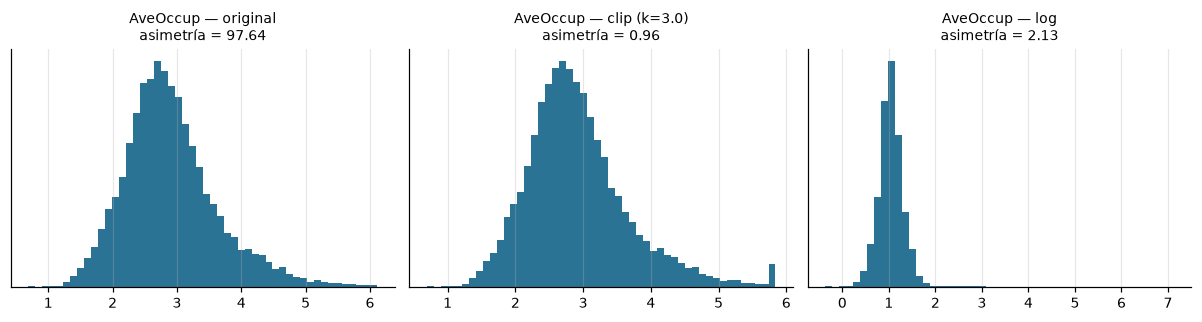

In [18]:
t, var = efecto("AveOccup")
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, (nombre, v) in zip(axes, var.items()):
    tope = v.quantile(0.995) if nombre == "original" else v.max()
    ax.hist(v[v <= tope], bins=50, color=AZUL, alpha=0.85)
    ax.set_title(f"AveOccup — {nombre}\nasimetría = {v.skew():.2f}", fontsize=9)
    ax.set_yticks([])
plt.tight_layout()
plt.show()

✏️ **Pregunta 7.1.** Mira `AveOccup`: ¿qué le pasa a la correlación de Pearson con `MedHouseVal` al recortar? ¿Y a la de Spearman?
¿Qué te dice eso sobre lo que hacían los valores extremos con $r$? (Pista: el logaritmo y el recorte casi no cambian el *orden* de los datos; ¿por qué Spearman casi no se mueve?)

✏️ **Pregunta 7.2.** Para `Population` el logaritmo deja la asimetría **negativa**. ¿Qué significa que se haya «pasado»? ¿Es un problema?

✏️ **Pregunta 7.3.** Cambia `k` en `efecto(c, k=3.0)` por `1.5` y compara. ¿Cuánta información pierdes al recortar con un $k$ más agresivo?

**Respuesta:**

En `AveOccup`, Pearson cambia de -0.024 a -0.271 con recorte a $3\,IQR$ (-0.281 con
$1.5\,IQR$), mientras Spearman permanece alrededor de -0.257. Los extremos estaban aplastando la
relación lineal. Spearman casi no cambia porque usa rangos: el recorte conserva prácticamente el
orden, aunque reduzca la magnitud de los máximos.

El logaritmo de `Population` lleva la asimetría de 4.94 a -1.04: comprimió tanto la cola derecha
que dejó una cola izquierda. No es automáticamente un problema; la transformación debe elegirse
por su utilidad para el modelo y la interpretación, no por forzar asimetría cero.

El umbral $1.5\,IQR$ es más agresivo. Por ejemplo, recorta 711 valores de `AveOccup`, 511 de
`AveRooms` y 1 196 de `Population`, frente a 132, 180 y 421 con $3\,IQR$. Aunque `clip` no elimina
filas, sí reemplaza más valores y borra diferencias en la cola; por eso usaría $3\,IQR$ y validaría
la decisión con el desempeño fuera de muestra.


### Aplicar sus decisiones

Completa el diccionario con la acción que elijas para cada variable: `"ninguno"`, `"clip"` o `"log"`.
La función `aplicar` crea una copia transformada; luego comparamos la asimetría antes y después.

> ⚠️ **Fugas.** Aquí calculamos las cercas con *todos* los datos para simplificar. En un proyecto real, las cercas (y medias, etc.) se
> calculan **solo con el conjunto de entrenamiento** y se reutilizan en validación y prueba (como vimos en la sesión 1).

In [19]:
decisiones = {        # ✏️ cambia las decisiones y vuelve a ejecutar esta celda y las siguientes
    "MedInc": "ninguno",
    "HouseAge": "ninguno",
    "AveRooms": "clip",
    "AveBedrms": "clip",
    "Population": "log",
    "AveOccup": "clip",
    "Latitude": "ninguno",
    "Longitude": "ninguno",
}

def aplicar(d, decisiones, k=3.0):
    out = d.copy()
    for c, accion in decisiones.items():
        if accion == "clip":
            out[c] = out[c].clip(*cercas_iqr(out[c], k))
        elif accion == "log":
            out[c] = logaritmo(out[c])
        elif accion != "ninguno":
            raise ValueError(f"acción desconocida para {c}: {accion!r}")
    return out

df_t = aplicar(df, decisiones)
comp = pd.DataFrame({"asimetria_antes": df.skew(), "asimetria_despues": df_t.skew(),
                     "curtosis_antes": df.kurt(), "curtosis_despues": df_t.kurt()})
comp.round(2)

,asimetria_antes,asimetria_despues,curtosis_antes,curtosis_despues
MedInc,1.65,1.65,4.95,4.95
HouseAge,0.06,0.06,-0.80,-0.80
AveRooms,20.70,0.89,879.35,2.23
AveBedrms,31.32,1.17,1636.71,2.61
Population,4.94,-1.04,73.55,4.48
AveOccup,97.64,0.96,10651.01,1.65
Latitude,0.47,0.47,-1.12,-1.12
Longitude,-0.30,-0.30,-1.33,-1.33
MedHouseVal,0.98,0.98,0.33,0.33


---
## Parte 8 — Análisis bivariado

Con $n=20\,640$ puntos, una dispersión simple se **satura** (puntos encimados). Comparamos con un *hexbin*, que cuenta puntos por celda,
y miramos `MedHouseVal` por grupos de ingreso.

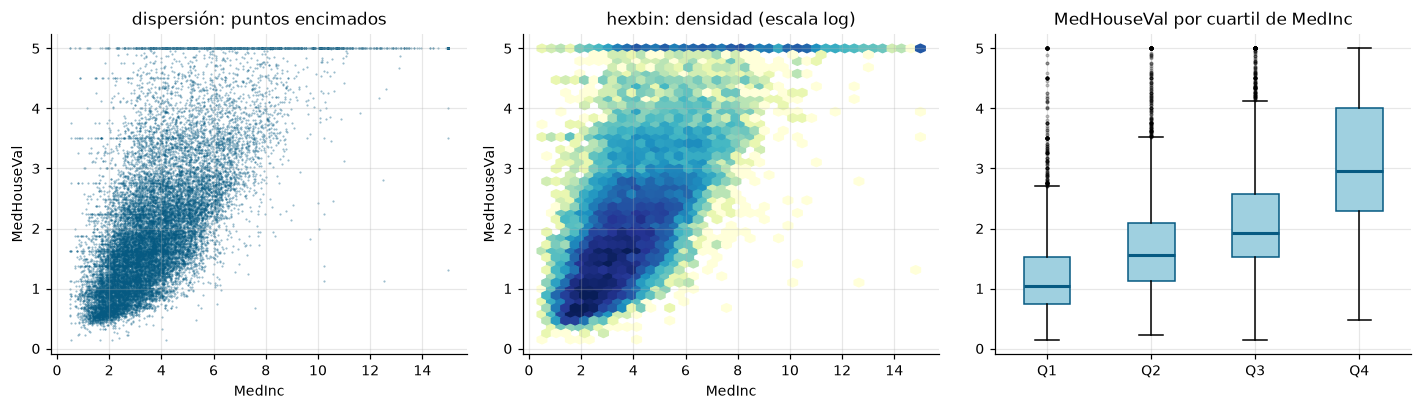

r de Pearson = 0.688    rho de Spearman = 0.677


In [20]:
X_NOMBRE = "MedInc"        # ✏️ cambia la variable y vuelve a ejecutar (prueba AveOccup, HouseAge, Latitude…)
Y_NOMBRE = "MedHouseVal"

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].scatter(df[X_NOMBRE], df[Y_NOMBRE], s=2, color=AZUL, alpha=0.4, lw=0)
axes[0].set_title("dispersión: puntos encimados")
hb = axes[1].hexbin(df[X_NOMBRE], df[Y_NOMBRE], gridsize=40, cmap="YlGnBu", mincnt=1, bins="log")
axes[1].set_title("hexbin: densidad (escala log)")
grupos = pd.qcut(df[X_NOMBRE], 4, labels=["Q1", "Q2", "Q3", "Q4"])
axes[2].boxplot([df.loc[grupos == g, Y_NOMBRE] for g in grupos.cat.categories], patch_artist=True,
                boxprops=dict(facecolor="#9FD0E0", edgecolor=AZUL), medianprops=dict(color=AZUL, lw=2),
                flierprops=dict(markersize=1.5, alpha=0.3))
axes[2].set_xticklabels(grupos.cat.categories)
axes[2].set_title(f"{Y_NOMBRE} por cuartil de {X_NOMBRE}")
for ax in axes[:2]:
    ax.set_xlabel(X_NOMBRE); ax.set_ylabel(Y_NOMBRE)
plt.tight_layout()
plt.show()
print(f"r de Pearson = {df[X_NOMBRE].corr(df[Y_NOMBRE]):.3f}    rho de Spearman = {df[X_NOMBRE].corr(df[Y_NOMBRE], method='spearman'):.3f}")

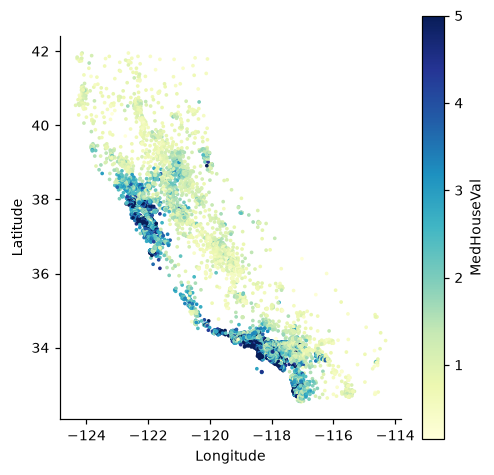

In [21]:
# Mapa: la ubicación también cuenta
plt.figure(figsize=(5, 5))
sc = plt.scatter(df["Longitude"], df["Latitude"], c=df["MedHouseVal"], s=2, cmap="YlGnBu")
plt.colorbar(sc, label="MedHouseVal")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.gca().set_aspect(1.2)
plt.grid(False)
plt.show()

✏️ **Pregunta 8.1.** En la primera gráfica (`MedInc` vs `MedHouseVal`), ¿qué es la línea horizontal de puntos arriba? ¿Cómo la relacionas con la Parte 6?
¿Qué ventaja da el hexbin sobre la dispersión?

✏️ **Pregunta 8.2.** ¿Cómo cambia la mediana de `MedHouseVal` al pasar de Q1 a Q4 de ingreso? ¿Es monótona?

✏️ **Pregunta 8.3.** En el mapa, ¿dónde están los distritos más caros? ¿Qué otro factor (distinto de `MedInc`)
podría estar influyendo tanto en el ingreso como en el precio? (recuerda *correlación ≠ causalidad*)

**Respuesta:**

La línea horizontal superior es el tope de `MedHouseVal` en 5.0: valores reales mayores quedaron
registrados con la misma cifra. El hexbin permite ver dónde se concentra la muestra cuando 20 640
puntos se enciman; el color muestra densidad y evita confundir una mancha saturada con una región
uniforme.

La mediana de `MedHouseVal` sube de **1.039** en Q1 a **1.563**, **1.933** y **2.952** en Q4; el
aumento es monótono. En el mapa, los valores altos se concentran sobre todo cerca de la costa y de
los principales centros urbanos. La ubicación puede elevar a la vez ingreso y precio, de modo que
la correlación con `MedInc` no basta para afirmar causalidad.


---
## Parte 9 — Matriz de correlación, heatmap y multicolinealidad

Con 9 variables hay $\binom92=36$ pares. La matriz $R=\frac1{n-1}Z^\top Z$ (con $Z$ las columnas estandarizadas) los resume.
Seguimos las buenas prácticas de la presentación: escala **divergente centrada en 0**, solo el **triángulo inferior** y **valores anotados**.

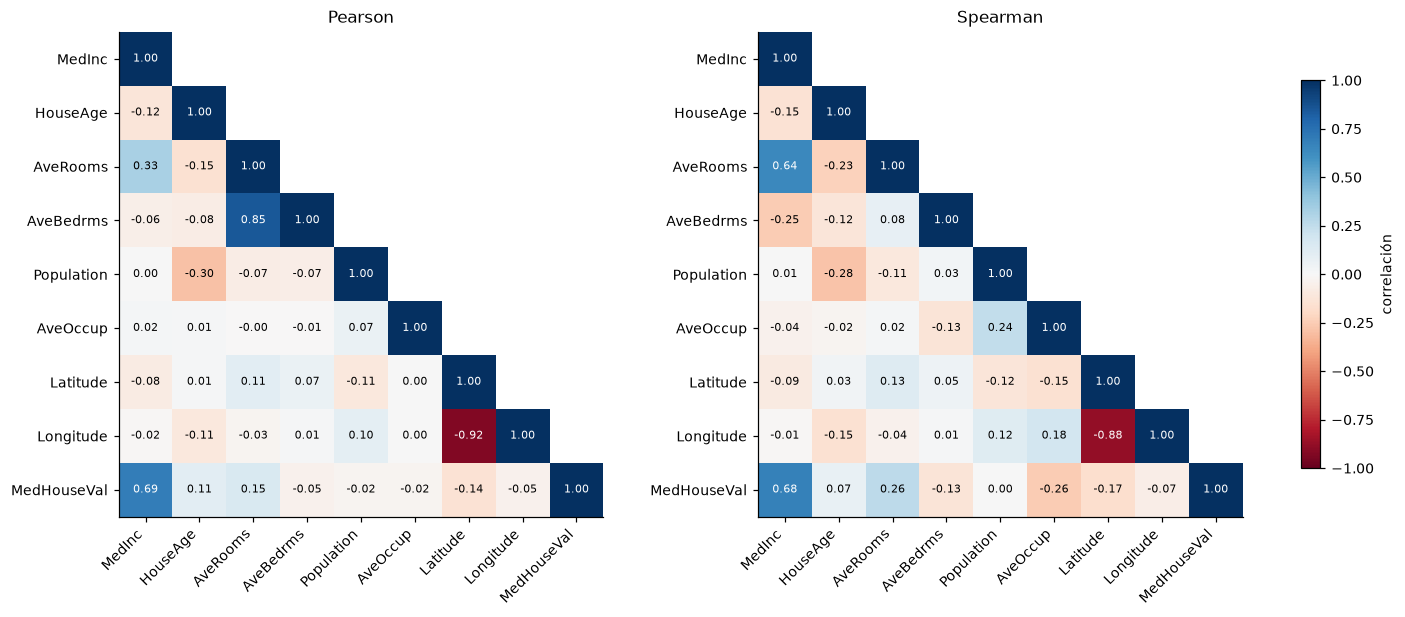

In [22]:
def heatmap(Cm, ax, titulo):
    mask = np.triu(np.ones(Cm.shape, dtype=bool), k=1)           # oculta el triángulo superior (es repetido)
    im = ax.imshow(np.ma.array(Cm.values, mask=mask), cmap="RdBu", vmin=-1, vmax=1)
    n = len(Cm)
    ax.set_xticks(range(n)); ax.set_xticklabels(Cm.columns, rotation=45, ha="right")
    ax.set_yticks(range(n)); ax.set_yticklabels(Cm.index)
    ax.grid(False)
    for i in range(n):
        for j in range(i + 1):
            v = Cm.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else "black")
    ax.set_title(titulo)
    return im

Cp = df.corr()                         # Pearson
Cs = df.corr(method="spearman")        # Spearman = Pearson de los rangos
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
heatmap(Cp, axes[0], "Pearson")
im = heatmap(Cs, axes[1], "Spearman")
fig.colorbar(im, ax=axes, shrink=0.8, label="correlación")
plt.show()

In [23]:
# Los pares más fuertes (sin repetir y sin la diagonal)
tri = np.tril(np.ones(Cp.shape, dtype=bool), k=-1)
pares = Cp.where(tri).stack().rename("pearson").to_frame()
pares["spearman"] = Cs.where(tri).stack()
pares["|pearson|"] = pares["pearson"].abs()
pares.sort_values("|pearson|", ascending=False).head(6).round(2)

,,pearson,spearman,|pearson|
Longitude,Latitude,-0.92,-0.88,0.92
AveBedrms,AveRooms,0.85,0.08,0.85
MedHouseVal,MedInc,0.69,0.68,0.69
AveRooms,MedInc,0.33,0.64,0.33
Population,HouseAge,-0.30,-0.28,0.30
AveRooms,HouseAge,-0.15,-0.23,0.15


In [24]:
# Pearson vs Spearman con el objetivo: ¿en qué variables difieren más?
vs = pd.DataFrame({"pearson": Cp["MedHouseVal"], "spearman": Cs["MedHouseVal"]}).drop("MedHouseVal")
vs["diferencia"] = (vs["spearman"] - vs["pearson"]).abs()
vs.sort_values("diferencia", ascending=False).round(2)

,pearson,spearman,diferencia
AveOccup,-0.02,-0.26,0.23
AveRooms,0.15,0.26,0.11
AveBedrms,-0.05,-0.13,0.08
HouseAge,0.11,0.07,0.03
Population,-0.02,0.00,0.03
Longitude,-0.05,-0.07,0.02
Latitude,-0.14,-0.17,0.02
MedInc,0.69,0.68,0.01


✏️ **Pregunta 9.1.** ¿Qué variable se correlaciona más con el objetivo? ¿Cuál es el par de variables **predictoras** más correlacionado (Pearson)? ¿Y el segundo?
¿Tienen sentido en el contexto (geografía, tamaño de las viviendas)?

✏️ **Pregunta 9.2.** ¿En qué variable difieren más Pearson y Spearman con el objetivo? Mira también el par `AveBedrms`–`AveRooms`: ¿qué le pasa a su correlación al pasar de Pearson a Spearman?
Conecta con lo que viste en las Partes 4, 5 y 7: ¿qué estaban haciendo los atípicos con $r$? ¿Qué implica para decir que dos variables son «redundantes»?

**Respuesta:**

`MedInc` es la variable con mayor correlación con el objetivo (Pearson 0.688). Entre predictores, el
par más correlacionado es `Latitude`–`Longitude` (-0.925), coherente con la geometría de la costa;
el segundo es `AveRooms`–`AveBedrms` (0.848), pues ambas son razones calculadas con el mismo número
de hogares.

La mayor diferencia Pearson–Spearman con el objetivo aparece en `AveOccup`: -0.024 frente a
-0.257. En `AveRooms`–`AveBedrms`, Pearson baja de 0.848 a solo 0.082 al usar rangos. Unos pocos
distritos con denominadores muy pequeños inflan la relación lineal. Antes de declarar variables
redundantes, revisaría dispersión, extremos y una medida robusta; no usaría un único coeficiente.


### Multicolinealidad

Con predictores muy correlacionados, los coeficientes de una regresión lineal se vuelven inestables. El **factor de inflación de la varianza**
mide qué tan bien se explica cada predictor con los demás:

$$\mathrm{VIF}_j=\frac{1}{1-R_j^2}\;=\;\big[R^{-1}\big]_{jj}\quad(\text{el }j\text{-ésimo elemento de la diagonal de la inversa de la matriz de correlación}).$$

Regla práctica: $\mathrm{VIF}>5$–$10$ es una alerta.

In [25]:
def vif(X):
    R = X.corr().values
    return pd.Series(np.diag(np.linalg.inv(R)), index=X.columns, name="VIF")

X = df.drop(columns="MedHouseVal")
vif(X).round(1)

MedInc        2.5
HouseAge      1.2
AveRooms      8.3
AveBedrms     7.0
Population    1.1
AveOccup      1.0
Latitude      9.3
Longitude     9.0
Name: VIF, dtype: float64

✏️ **Pregunta 9.3.** ¿Qué variables tienen VIF alto? ¿Las habías anticipado con el heatmap? ¿Esa colinealidad es «real» para todo el conjunto o la crean unos pocos distritos extremos? (revisa los Spearman de la Parte 9)

✏️ **Pregunta 9.4.** Quita **una** de las variables con VIF alto (la que consideres más redundante, p. ej. `AveBedrms`) en la celda de abajo y vuelve a calcular.
¿Cuánto baja el VIF de su «pareja»? ¿Qué variable elegirías conservar y por qué?

**Respuesta:**

Los VIF altos son `Latitude` (9.30), `Longitude` (8.96), `AveRooms` (8.34) y `AveBedrms` (6.99),
como sugería el heatmap de Pearson. La dependencia geográfica se mantiene también con Spearman y
es estructural; en cambio, la pareja habitaciones–dormitorios cae a 0.082 con Spearman, por lo que
gran parte de su aparente colinealidad proviene de distritos extremos.

Al quitar `AveBedrms`, el VIF de `AveRooms` baja de 8.34 a **1.26**. Conservaría `AveRooms` porque
expresa el tamaño total de la vivienda y tiene una asociación más clara con `MedHouseVal`. Aun así,
la elección final debe hacerse dentro de validación cruzada, no solo con VIF.


In [26]:
# ✏️ Pregunta 9.4: elige qué variable quitar y compara
a_quitar = ["AveBedrms"]
vif(X.drop(columns=a_quitar)).round(1)

MedInc        1.3
HouseAge      1.2
AveRooms      1.3
Population    1.1
AveOccup      1.0
Latitude      8.8
Longitude     8.7
Name: VIF, dtype: float64

---
## Parte 10 — Resumen y entregable

Rellena la tabla con **una fila por variable predictora**. La columna `pct_atipicos` ya está calculada con la regla del IQR ($k=1.5$);
las columnas `decision` y `justificacion` las completas tú.

| variable | % atípicos | decisión | justificación |
|---|---|---|---|
| *(ejemplo)* `AveOccup` | 3.4 | `clip` en $3\cdot$IQR | casi todos los distritos tienen ≈3 ocupantes; los valores > 50 corresponden a distritos con muy pocos hogares (residencias colectivas) y arrastran la media y a $r$ |

Una buena justificación responde: **¿por qué es (o no) un error?**, **¿qué pasaría con el análisis si lo dejamos?** y **¿cómo documento la decisión?**

In [27]:
entrega = tabla_atipicos(df.drop(columns="MedHouseVal"), 1.5)[["pct_atipicos"]].round(1).copy()
criterios = {
    "MedInc": ("ninguno", "Cola derecha real; conservar para no comprimir la señal socioeconómica. Probar log solo dentro de validación."),
    "HouseAge": ("indicador de tope", "No tiene atípicos por IQR, pero 1 273 filas están censuradas en 52; conservar y marcar el tope."),
    "AveRooms": ("clip en 3·IQR", "Los máximos provienen de distritos con pocos hogares e inflan Pearson; el recorte conserva las filas."),
    "AveBedrms": ("clip en 3·IQR", "Comparte denominador con AveRooms y unos pocos extremos crean colinealidad aparente."),
    "Population": ("log1p", "Es un conteo positivo con cola larga; log1p reduce la escala sin perder distritos."),
    "AveOccup": ("marcar hogares < 10 y clip en 3·IQR", "Los máximos representan distritos colectivos y aplastan Pearson; separar 51 filas y limitar el resto."),
    "Latitude": ("ninguno", "Rango geográfico acotado y 0 % de atípicos; mantiene la estructura espacial."),
    "Longitude": ("ninguno", "Rango geográfico acotado y 0 % de atípicos; se conserva aunque colinee con Latitude."),
}
for variable, (decision, justificacion) in criterios.items():
    entrega.loc[variable, "decision"] = decision
    entrega.loc[variable, "justificacion"] = justificacion
pd.set_option("display.max_colwidth", 100)
entrega

,pct_atipicos,decision,justificacion
variable,,,
MedInc,3.3,ninguno,Cola derecha real; conservar para no comprimir la señal socioeconómica. Probar log solo dentro d...
HouseAge,0.0,indicador de tope,"No tiene atípicos por IQR, pero 1 273 filas están censuradas en 52; conservar y marcar el tope."
AveRooms,2.5,clip en 3·IQR,Los máximos provienen de distritos con pocos hogares e inflan Pearson; el recorte conserva las f...
AveBedrms,6.9,clip en 3·IQR,Comparte denominador con AveRooms y unos pocos extremos crean colinealidad aparente.
Population,5.8,log1p,Es un conteo positivo con cola larga; log1p reduce la escala sin perder distritos.
AveOccup,3.4,marcar hogares < 10 y clip en 3·IQR,Los máximos representan distritos colectivos y aplastan Pearson; separar 51 filas y limitar el r...
Latitude,0.0,ninguno,Rango geográfico acotado y 0 % de atípicos; mantiene la estructura espacial.
Longitude,0.0,ninguno,Rango geográfico acotado y 0 % de atípicos; se conserva aunque colinee con Latitude.


In [28]:
# Cuando termines, guarda la tabla y súbela junto con este notebook
# (edita primero las columnas «decision» y «justificacion» en la celda anterior, p. ej. con entrega.loc["AveOccup", "decision"] = "clip")
entrega.to_csv("practica-eda-decisiones.csv", encoding="utf-8")
print("Guardado: practica-eda-decisiones.csv")

Guardado: practica-eda-decisiones.csv


### Reflexión final (3–5 líneas)

1. ¿Qué hallazgo del EDA **cambiaría** la forma en que entrenarías un modelo para predecir `MedHouseVal`?
2. ¿Qué decisión de la tabla es la más **discutible** y qué evidencia adicional pedirías?
3. Dos *trampas* de la presentación que aparecieron en este conjunto de datos (por ejemplo: topes, correlaciones aplastadas por atípicos, multicolinealidad…).

**Respuesta:**

---
### Reto opcional

Compara la regla del IQR con la regla del puntaje $z$ ($|z|>3$) en `AveOccup` y en `MedInc`: ¿cuántos puntos marca cada una?
¿Cuál es más sensible a los propios atípicos, y por qué? (Pista: el $z$ usa $\bar x$ y $s$, que los atípicos *contaminan*; el IQR usa cuartiles.)

El hallazgo que más cambiaría el entrenamiento es la censura de `MedHouseVal`: conservaría un
indicador del tope y separaría la evaluación de la zona censurada. La decisión más discutible es
recortar `AveOccup`; pediría el número real de hogares y el tipo de establecimiento antes de fijar
la regla. Las dos trampas más claras fueron tratar topes como atípicos y aceptar correlaciones de
Pearson infladas o aplastadas por unas cuantas filas extremas.

**Reto opcional.** El IQR marca 711 casos en `AveOccup` y 681 en `MedInc`; $|z|>3$ marca solo 8 y
345, respectivamente. El puntaje z es más sensible a la contaminación porque sus propios
parámetros, media y desviación estándar, se desplazan e inflan con los extremos. Los cuartiles del
IQR son mucho más robustos.


In [29]:
# Reto opcional: IQR vs |z| > 3
for c in ["AveOccup", "MedInc"]:
    x = df[c]
    lo, hi = cercas_iqr(x, 1.5)
    n_iqr = int(((x < lo) | (x > hi)).sum())
    n_z = int((((x - x.mean()) / x.std()).abs() > 3).sum())
    print(f"{c:9s}: IQR(1.5) marca {n_iqr:5d}   |z|>3 marca {n_z:5d}")

AveOccup : IQR(1.5) marca   711   |z|>3 marca     8
MedInc   : IQR(1.5) marca   681   |z|>3 marca   345
